# Day 24: Data Type Cleaning

## Objective
Identify incorrect data types and convert columns to appropriate data types.

## Tools
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

## Tasks
1. Create a sample employee dataset.
2. Inspect original data types.
3. Convert columns to suitable data types.
4. Verify the converted data types.
5. Explain the conversions.
6. Visualize the before-and-after results.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = {
    "Employee_ID": [101, 102, 103, 104, 105, 106],
    "Name": ["Aman", "Priya", "Rahul", "Neha", "Rohan", "Simran"],
    "Age": ["24", "27", "25", "29", "26", "28"],
    "Salary": ["35000", "48000", "42000", "55000", "45000", "52000"],
    "Experience": ["1.5", "3.0", "2.0", "5.0", "2.5", "4.0"],
    "Joining_Date": [
        "2024-01-15", "2022-06-10", "2023-03-20",
        "2020-11-05", "2022-09-12", "2021-04-18"
    ],
    "Department": [
        "IT", "HR", "IT", "Finance", "Sales", "HR"
    ]
}

df = pd.DataFrame(data)

print("Original Dataset:")
display(df)

Original Dataset:


,Employee_ID,Name,Age,Salary,Experience,Joining_Date,Department
0,101,Aman,24,35000,1.5,2024-01-15,IT
1,102,Priya,27,48000,3.0,2022-06-10,HR
2,103,Rahul,25,42000,2.0,2023-03-20,IT
3,104,Neha,29,55000,5.0,2020-11-05,Finance
4,105,Rohan,26,45000,2.5,2022-09-12,Sales
5,106,Simran,28,52000,4.0,2021-04-18,HR


In [3]:
print("Original column data types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Original column data types:
Employee_ID     int64
Name              str
Age               str
Salary            str
Experience        str
Joining_Date      str
Department        str
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Employee_ID   6 non-null      int64
 1   Name          6 non-null      str  
 2   Age           6 non-null      str  
 3   Salary        6 non-null      str  
 4   Experience    6 non-null      str  
 5   Joining_Date  6 non-null      str  
 6   Department    6 non-null      str  
dtypes: int64(1), str(6)
memory usage: 468.0 bytes


In [4]:
original_dtypes = df.dtypes.astype(str).copy()

print("Original Data Types:")
display(original_dtypes.rename("Original Data Type").to_frame())

Original Data Types:


,Original Data Type
Employee_ID,int64
Name,str
Age,str
Salary,str
Experience,str
Joining_Date,str
Department,str


In [5]:
# Convert text numbers into numeric values
df["Age"] = pd.to_numeric(df["Age"]).astype("int64")
df["Salary"] = pd.to_numeric(df["Salary"]).astype("int64")
df["Experience"] = pd.to_numeric(df["Experience"])

# Convert text dates into datetime
df["Joining_Date"] = pd.to_datetime(
    df["Joining_Date"],
    format="%Y-%m-%d"
)

# Convert department into a categorical type
df["Department"] = df["Department"].astype("category")

print("Data types converted successfully!")
display(df.head())

Data types converted successfully!


,Employee_ID,Name,Age,Salary,Experience,Joining_Date,Department
0,101,Aman,24,35000,1.5,2024-01-15,IT
1,102,Priya,27,48000,3.0,2022-06-10,HR
2,103,Rahul,25,42000,2.0,2023-03-20,IT
3,104,Neha,29,55000,5.0,2020-11-05,Finance
4,105,Rohan,26,45000,2.5,2022-09-12,Sales


In [6]:
corrected_dtypes = df.dtypes.astype(str)

dtype_comparison = pd.DataFrame({
    "Original Data Type": original_dtypes,
    "Corrected Data Type": corrected_dtypes
})

display(dtype_comparison)

,Original Data Type,Corrected Data Type
Employee_ID,int64,int64
Name,str,str
Age,str,int64
Salary,str,int64
Experience,str,float64
Joining_Date,str,datetime64[us]
Department,str,category


In [7]:
conversion_explanation = pd.DataFrame({
    "Column": [
        "Age",
        "Salary",
        "Experience",
        "Joining_Date",
        "Department"
    ],
    "Before": [
        "object",
        "object",
        "object",
        "object",
        "object"
    ],
    "After": [
        str(df["Age"].dtype),
        str(df["Salary"].dtype),
        str(df["Experience"].dtype),
        str(df["Joining_Date"].dtype),
        str(df["Department"].dtype)
    ],
    "Reason": [
        "Age is a whole-number quantity",
        "Salary is used for numerical calculations",
        "Experience may contain decimal values",
        "Dates support date-based operations",
        "Department contains a limited set of labels"
    ]
})

display(conversion_explanation)

,Column,Before,After,Reason
0,Age,object,int64,Age is a whole-number quantity
1,Salary,object,int64,Salary is used for numerical calculations
2,Experience,object,float64,Experience may contain decimal values
3,Joining_Date,object,datetime64[us],Dates support date-based operations
4,Department,object,category,Department contains a limited set of labels


In [8]:
print("Corrected data types:")
print(df.dtypes)

print("\nMissing values after conversion:")
print(df.isnull().sum())

print("\nAverage salary:", df["Salary"].mean())
print("Average age:", df["Age"].mean())

print("\nEarliest joining date:", df["Joining_Date"].min())
print("Latest joining date:", df["Joining_Date"].max())

Corrected data types:
Employee_ID              int64
Name                       str
Age                      int64
Salary                   int64
Experience             float64
Joining_Date    datetime64[us]
Department            category
dtype: object

Missing values after conversion:
Employee_ID     0
Name            0
Age             0
Salary          0
Experience      0
Joining_Date    0
Department      0
dtype: int64

Average salary: 46166.666666666664
Average age: 26.5

Earliest joining date: 2020-11-05 00:00:00
Latest joining date: 2024-01-15 00:00:00


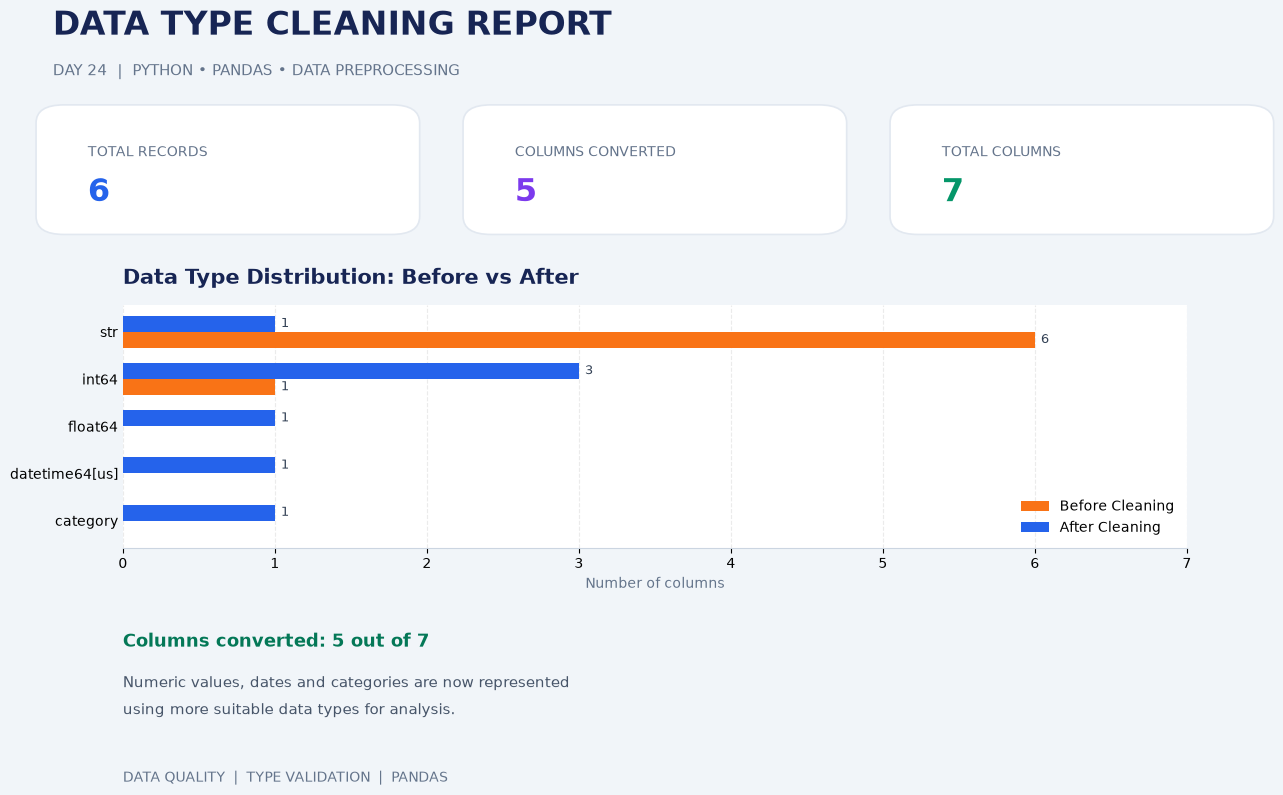

In [9]:
from matplotlib.patches import FancyBboxPatch

# Count data types before and after conversion
before_counts = original_dtypes.value_counts()
after_counts = corrected_dtypes.value_counts()

all_types = sorted(set(before_counts.index) | set(after_counts.index))

before_values = [int(before_counts.get(t, 0)) for t in all_types]
after_values = [int(after_counts.get(t, 0)) for t in all_types]

converted_columns = int(
    (original_dtypes != corrected_dtypes).sum()
)
total_columns = len(df.columns)
total_rows = len(df)

fig = plt.figure(figsize=(14, 9), facecolor="#F1F5F9")

fig.text(
    0.07, 0.93,
    "DATA TYPE CLEANING REPORT",
    fontsize=24, fontweight="bold", color="#172554"
)

fig.text(
    0.07, 0.885,
    "DAY 24  |  PYTHON • PANDAS • DATA PREPROCESSING",
    fontsize=11, color="#64748B"
)

def add_card(x, title, value, color):
    card = FancyBboxPatch(
        (x, 0.72), 0.25, 0.12,
        boxstyle="round,pad=0.012,rounding_size=0.02",
        transform=fig.transFigure,
        facecolor="white",
        edgecolor="#E2E8F0",
        linewidth=1.2
    )
    fig.patches.append(card)

    fig.text(
        x + 0.025, 0.795,
        title, fontsize=10, color="#64748B"
    )
    fig.text(
        x + 0.025, 0.745,
        value, fontsize=23, fontweight="bold", color=color
    )

add_card(0.07, "TOTAL RECORDS", f"{total_rows}", "#2563EB")
add_card(0.375, "COLUMNS CONVERTED", f"{converted_columns}", "#7C3AED")
add_card(0.68, "TOTAL COLUMNS", f"{total_columns}", "#059669")

# Compare data type distributions
ax = fig.add_axes([0.12, 0.36, 0.76, 0.27])
ax.set_facecolor("white")

positions = list(range(len(all_types)))
bar_height = 0.34

bars_before = ax.barh(
    [p - bar_height / 2 for p in positions],
    before_values,
    height=bar_height,
    label="Before Cleaning",
    color="#F97316"
)

bars_after = ax.barh(
    [p + bar_height / 2 for p in positions],
    after_values,
    height=bar_height,
    label="After Cleaning",
    color="#2563EB"
)

ax.set_yticks(positions)
ax.set_yticklabels(all_types)
ax.set_title(
    "Data Type Distribution: Before vs After",
    loc="left", fontsize=15, fontweight="bold",
    color="#172554", pad=15
)
ax.set_xlabel("Number of columns", color="#64748B")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")
ax.tick_params(axis="y", length=0)

for bars in [bars_before, bars_after]:
    for bar in bars:
        if bar.get_width() > 0:
            ax.text(
                bar.get_width() + 0.04,
                bar.get_y() + bar.get_height() / 2,
                f"{int(bar.get_width())}",
                va="center", fontsize=9, color="#334155"
            )

ax.set_xlim(0, max(before_values + after_values + [1]) + 1)

# Conversion summary
fig.text(
    0.12, 0.25,
    f"Columns converted: {converted_columns} out of {total_columns}",
    fontsize=13, fontweight="bold", color="#047857"
)

fig.text(
    0.12, 0.205,
    "Numeric values, dates and categories are now represented",
    fontsize=11, color="#475569"
)
fig.text(
    0.12, 0.175,
    "using more suitable data types for analysis.",
    fontsize=11, color="#475569"
)

fig.text(
    0.12, 0.10,
    "DATA QUALITY  |  TYPE VALIDATION  |  PANDAS",
    fontsize=10, color="#64748B"
)

plt.savefig(
    "data_type_cleaning_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

In [10]:
df.to_csv("cleaned_employee_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
